[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/02-data-validation.ipynb)

# Data Acquisition and Validation

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Record the provenance of a dataset, including a checksum of the exact file.</li>
<li>Write validation checks with severities and documented tolerances for known issues.</li>
<li>Use domain knowledge and time-coverage views to find problems no type check can.</li>
<li>Prove a validation suite works by deliberately corrupting a copy of the data.</li>
</ul>
</div>

**Prerequisites:** <a href="../01-problem-framing/">Problem Framing</a>. **Dataset:** Online Retail II. **Time:** about 30 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

A model is only as trustworthy as its data, and data arrives from places you do not control: an export, a vendor, a colleague's spreadsheet. The most expensive data bug is the one nobody notices, because the model trains happily on garbage and reports a number.

The remedy is the same as in software: **write down what you expect, and test it automatically every time the data changes.** This page does that for our retail file. We deliberately validate the **raw** data, before any cleaning, because validation answers *"can I trust what I was given?"* and cleaning answers *"what shall I do about it?"*, which is the next page.

## Know what you were given

Before checking values, pin down *which* data this is. Two files with the same name can hold different numbers.

<div class="admonition note">
<p class="admonition-title">Provenance in one table</p>
<p>Who published it, when it was retrieved, under what licence, and a fingerprint of the exact bytes. The fingerprint is what lets you say "this result was produced on <em>that</em> data" six months later.</p>
</div>

In [2]:
import hashlib
from mlp_data import data_dir

src = data_dir() / "raw" / "online_retail_II.xlsx"
sha = hashlib.sha256(src.read_bytes()).hexdigest()
expected = "bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980"   # recorded in data/README.md on 2026-10-15
pd.Series({
    "publisher": "UCI Machine Learning Repository (donated 2019)",
    "licence": "CC BY 4.0",
    "file": src.name,
    "size (MB)": round(src.stat().st_size / 1e6, 1),
    "sha256 (first 16)": sha[:16],
    "matches the version this course was written against": sha == expected,
}, name="provenance").to_frame()

,provenance
publisher,UCI Machine Learning Repository (donated 2019)
licence,CC BY 4.0
file,online_retail_II.xlsx
size (MB),45.60
sha256 (first 16),bcbe73b35f5b7bab
matches the version this course was written against,True


If that last row ever says `False`, the publisher changed the file and every number in this course may shift. `mlp_data` also warns you at download time; here we have simply made the idea visible.

## Write the expectations down

We encode each expectation as a small named check. Three ideas make the suite genuinely useful rather than noisy:

1. **Severity.** An `error` means we must not proceed. A `warn` means a human should look.
2. **Known issues.** Real data always violates *something*. If we have investigated a violation and accepted it, we record its size as **tolerated**. The check then shows `KNOWN`, and fails only if the count *grows*, which is exactly the signal that something new has gone wrong.
3. **Domain checks.** The most valuable expectations come from understanding the business, not from the column types.

In [3]:
from dataclasses import dataclass
from typing import Callable

@dataclass
class Check:
    name: str
    severity: str                     # "error" stops the pipeline, "warn" asks for a human look
    violations: Callable              # df -> number of offending rows (or items)
    tolerated: int = 0                # size of an investigated, accepted problem
    why: str = ""

def run_checks(df, checks):
    rows = []
    for c in checks:
        try:
            n = int(c.violations(df))
            status = "PASS" if n == 0 else ("KNOWN" if n <= c.tolerated else "FAIL")
        except Exception as e:                      # a check that cannot run is itself a failure
            n, status = np.nan, f"CANNOT RUN ({type(e).__name__})"
        rows.append((c.name, c.severity, n, c.tolerated, status, c.why))
    return pd.DataFrame(rows, columns=["check", "severity", "violations", "tolerated", "status", "why"])

EXPECTED_SCHEMA = {   # column -> predicate on the dtype (robust across pandas versions)
    "Invoice": pd.api.types.is_string_dtype, "StockCode": pd.api.types.is_string_dtype,
    "Description": pd.api.types.is_string_dtype, "Quantity": pd.api.types.is_integer_dtype,
    "InvoiceDate": pd.api.types.is_datetime64_any_dtype, "Price": pd.api.types.is_float_dtype,
    "Customer ID": pd.api.types.is_float_dtype, "Country": pd.api.types.is_string_dtype}

def schema_problems(d):
    missing = [c for c in EXPECTED_SCHEMA if c not in d.columns]
    wrong = [c for c, ok in EXPECTED_SCHEMA.items() if c in d.columns and not ok(d[c])]
    return len(missing) + len(wrong) + len([c for c in d.columns if c not in EXPECTED_SCHEMA])

by_invoice = lambda d, col: d.groupby("Invoice")[col].nunique().gt(1).sum()

CHECKS = [
    Check("columns and dtypes are as expected", "error", schema_problems, 0, "downstream code assumes these names"),
    Check("row count equals the validated file (1,067,371)", "error", lambda d: abs(len(d) - 1_067_371), 0, "truncated or doubled download"),
    Check("no nulls in Invoice, StockCode, Quantity, InvoiceDate, Price", "error",
          lambda d: d[["Invoice", "StockCode", "Quantity", "InvoiceDate", "Price"]].isna().any(axis=1).sum(), 0, "core fields"),
    Check("InvoiceDate within 2009-12-01 .. 2011-12-10", "error",
          lambda d: (~d["InvoiceDate"].between("2009-12-01", "2011-12-10 23:59")).sum(), 0, "timestamps outside the trading period"),
    Check("Quantity is never 0", "error", lambda d: (d["Quantity"] == 0).sum(), 0, "a line that moves nothing"),
    Check("Price is never negative", "error", lambda d: (d["Price"] < 0).sum(), 5, "see the bad-debt adjustments below"),
    Check("Invoice looks like 123456 or C123456", "warn", lambda d: (~d["Invoice"].str.fullmatch(r"C?\d{6}")).sum(), 6, "see the A-invoices below"),
    Check("each invoice belongs to one customer", "error", lambda d: by_invoice(d, "Customer ID"), 0, "otherwise customer features are ambiguous"),
    Check("each invoice has one country", "error", lambda d: by_invoice(d, "Country"), 0, ""),
    Check("each invoice has one timestamp", "warn", lambda d: by_invoice(d, "InvoiceDate"), 83, "invoices keyed over several minutes"),
    Check("missing Customer ID is at most 25% of rows", "warn", lambda d: int(d["Customer ID"].isna().mean() > 0.25), 0, "guest checkouts; more would starve the model"),
    Check("missing Description is at most 1% of rows", "warn", lambda d: int(d["Description"].isna().mean() > 0.01), 0, ""),
    Check("UK share of rows is between 85% and 95%", "warn", lambda d: int(not 0.85 <= (d["Country"] == "United Kingdom").mean() <= 0.95), 0, "the customer mix changed"),
    Check("domain rule: almost no Saturday trading (< 0.1% of rows)", "warn", lambda d: int((d["InvoiceDate"].dt.dayofweek == 5).mean() > 0.001), 0, "the shop is closed; trading then means a timestamp problem"),
]

raw = load_retail()
report = run_checks(raw, CHECKS)
report[["check", "severity", "violations", "tolerated", "status"]]

,check,severity,violations,tolerated,status
0,columns and dtypes are as expected,error,0,0,PASS
1,"row count equals the validated file (1,067,371)",error,0,0,PASS
2,"no nulls in Invoice, StockCode, Quantity, Invo...",error,0,0,PASS
3,InvoiceDate within 2009-12-01 .. 2011-12-10,error,0,0,PASS
4,Quantity is never 0,error,0,0,PASS
5,Price is never negative,error,5,5,KNOWN
6,Invoice looks like 123456 or C123456,warn,6,6,KNOWN
7,each invoice belongs to one customer,error,0,0,PASS
8,each invoice has one country,error,0,0,PASS
9,each invoice has one timestamp,warn,83,83,KNOWN


**Reading the report.** Most checks pass. Three come back `KNOWN`: we have already looked at negative prices, odd invoice numbers and multi-timestamp invoices and decided to tolerate exactly that many. If next month's file had 600 negative prices, the status would flip to `FAIL` and stop the pipeline. A check that nobody has investigated is noise; a check with a documented, bounded tolerance is a tripwire.

Two of those known issues deserve a closer look, because they are not what you would guess.

In [4]:
odd = raw[~raw["Invoice"].str.fullmatch(r"C?\d{6}")][["Invoice", "StockCode", "Description", "Quantity", "Price", "Customer ID", "InvoiceDate"]]
odd.assign(Price=odd["Price"].map("{:,.2f}".format))

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
179403,A506401,B,Adjust bad debt,1,"-53,594.36",NaN,2010-04-29 13:36:00
276274,A516228,B,Adjust bad debt,1,"-44,031.79",NaN,2010-07-19 11:24:00
403472,A528059,B,Adjust bad debt,1,"-38,925.87",NaN,2010-10-20 12:04:00
825443,A563185,B,Adjust bad debt,1,"11,062.06",NaN,2011-08-12 14:50:00
825444,A563186,B,Adjust bad debt,1,"-11,062.06",NaN,2011-08-12 14:51:00
825445,A563187,B,Adjust bad debt,1,"-11,062.06",NaN,2011-08-12 14:52:00


<div class="admonition warning">
<p class="admonition-title">Accounting entries hiding in the sales file</p>
<p>These six rows are <strong>bad-debt adjustments</strong>, each a single line worth between about £11,000 and £54,000, with no customer attached. They are bookkeeping, not purchases. If they leaked into a "total spend" feature they would dwarf real behaviour. A column-type check would never find them; reading the rows did. This is why every validation suite should be grown from <em>looking at the data</em>, not only from its schema.</p>
</div>

## Does the data cover the period you think it does?

Row-level checks cannot see **missing time**. Two quick views: how much data each month holds, and which weekdays trade.

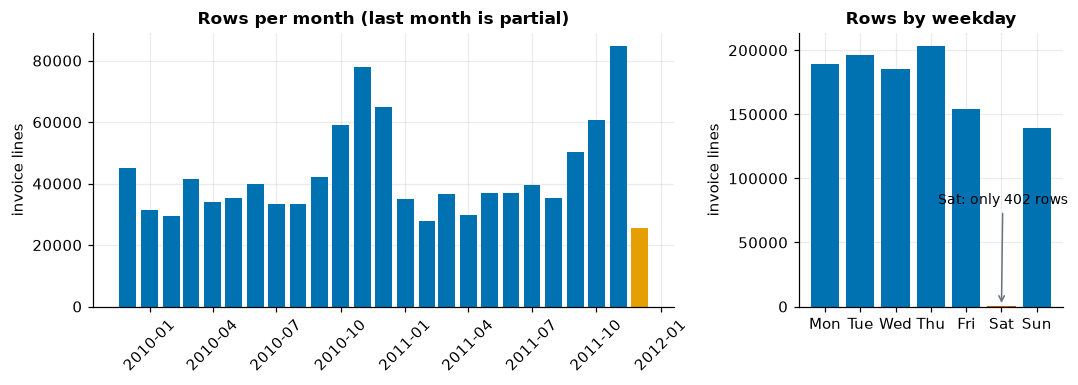

135 of 739 calendar days have no invoices; 104 of them are Saturdays


,start,days
3,2009-12-24,11
57,2010-12-24,11


In [5]:
monthly = raw.set_index("InvoiceDate").resample("MS").size()
weekday = raw["InvoiceDate"].dt.dayofweek.value_counts().sort_index()
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
colors = [style.BLUE] * (len(monthly) - 1) + [style.ORANGE]
a.bar(monthly.index, monthly.values, width=24, color=colors)
a.set(title="Rows per month (last month is partial)", ylabel="invoice lines"); a.tick_params(axis="x", rotation=45)
b.bar(names, [weekday.get(i, 0) for i in range(7)], color=[style.RED if n == "Sat" else style.BLUE for n in names])
b.set(title="Rows by weekday", ylabel="invoice lines")
b.annotate(f"Sat: only {weekday.get(5, 0)} rows", (5, weekday.get(5, 0)), (3.2, 80000), arrowprops=dict(arrowstyle="->", color=style.GREY), fontsize=9)
plt.tight_layout(); plt.show()

days_with_trade = raw["InvoiceDate"].dt.normalize().drop_duplicates()
calendar = pd.date_range(days_with_trade.min(), days_with_trade.max())
quiet = calendar.difference(days_with_trade)
print(f"{len(quiet)} of {len(calendar)} calendar days have no invoices; {(quiet.dayofweek == 5).sum()} of them are Saturdays")
runs = pd.Series(quiet).diff().dt.days.ne(1).cumsum()
longest = pd.Series(quiet).groupby(runs).agg(start="min", days="size").nlargest(2, "days")
longest

**Reading the charts.** Volume swings strongly through the year (the autumn build-up is clear) and the **orange last month is partial**, because the data stops on 9 December 2011. A model that treats that month as "low demand" would be wrong. Weekday trading shows **almost no Saturdays**, which is the business closing rather than missing data, and the longest quiet stretches are the two Christmas shutdowns of eleven days each.

None of this is a bug. It is *context* a modeller must know, and it tells us what a sensible validation rule is: Saturday trading would signal a timestamp problem, so we encoded it.

## Prove the checks can fail

A test that has never failed has not been shown to work. Corrupt a copy of the data in three realistic ways and rerun the suite.

In [6]:
bad = raw.copy()
bad.loc[bad.sample(500, random_state=0).index, "Price"] *= -1                      # sign errors
bad.loc[bad.sample(50, random_state=1).index, "InvoiceDate"] = pd.Timestamp("2030-01-01")   # impossible dates
bad = bad.rename(columns={"Country": "country_name"})                                # an upstream rename

after = run_checks(bad, CHECKS)
changed = after.merge(report[["check", "status"]], on="check", suffixes=("_now", "_before"))
changed[changed["status_now"] != changed["status_before"]][["check", "status_before", "status_now", "violations"]]

,check,status_before,status_now,violations
0,columns and dtypes are as expected,PASS,FAIL,2.00
3,InvoiceDate within 2009-12-01 .. 2011-12-10,PASS,FAIL,50.00
5,Price is never negative,KNOWN,FAIL,502.00
8,each invoice has one country,PASS,CANNOT RUN (KeyError),NaN
9,each invoice has one timestamp,KNOWN,FAIL,133.00
12,UK share of rows is between 85% and 95%,PASS,CANNOT RUN (KeyError),NaN


The suite catches all three: the sign errors push the negative-price count far past its tolerance, the impossible dates break the date-range check (and, as a bonus, the one-timestamp-per-invoice check, because rewriting dates splits invoices), and the rename breaks the schema check and stops the two checks that use `Country` from running (`CANNOT RUN` is a failure, not a pass). Without these checks, the rename would surface much later as a confusing `KeyError`, and the sign errors as a slightly worse model nobody could explain.

<div class="admonition tip">
<p class="admonition-title">Where this runs in a real project</p>
<p>At the <strong>entry</strong> of the pipeline, every time new data arrives: read, validate, and <em>stop on any <code>error</code></em>. Save the report next to the data. Libraries such as <code>pandera</code> and <code>Great Expectations</code> industrialise this idea; the principle is exactly what you just wrote in thirty lines.</p>
</div>

## Check yourself

<details class="question">
<summary>1. Why validate the raw data before cleaning it, rather than after?</summary>

Validation answers "can I trust what I was given, and has it changed?". If you validate *after* cleaning, your cleaning code may already have hidden the problem (for example, by dropping the rows that would have failed). Validate first, then decide what to do about each finding, and record those decisions.

</details>

<details class="question">
<summary>2. A check for negative prices is set to tolerate exactly 5 violations. Why not set it to 100 'to be safe'?</summary>

A loose tolerance hides regressions. The point of a tolerance is to document an **investigated** problem. With 5, a new batch containing 6 negative prices fails and gets looked at; with 100, a sixty-fold growth in bad data would pass silently.

</details>

<details class="question">
<summary>3. The last month in the data is partial. What mistake would that cause in a monthly sales forecast, and how do validation and planning guard against it?</summary>

The forecast would see a sharp drop in the final month and learn a false decline (or be evaluated unfairly on it). A coverage check that flags incomplete periods, and a rule that only complete periods enter training and evaluation, prevents it. Our snapshot design also stops the last label window before the data ends.

</details>

## Exercise

<details class="question">
<summary>Add a check that flags any non-adjustment invoice line with a unit price above £5,000. First guess how many there are, then run it.</summary>

```python
big = Check("no single unit costs more than 5,000 (excluding adjustments)", "warn",
            lambda d: ((d["Price"] > 5000) & ~d["StockCode"].isin(["B", "M", "AMAZONFEE"])).sum(), 0)
run_checks(raw, CHECKS + [big]).tail(1)
```

Whatever the count, the right next step is to **read those rows** before deciding to tolerate or fix them. If they are legitimate high-value items, record the count as `tolerated`; if they are errors, raise it with whoever owns the source.

</details>

## Recap

- Pin down provenance: publisher, licence, date, and a checksum of the exact file.
- Turn expectations into named checks with a **severity** and an **investigated tolerance**. `KNOWN` means "we have looked"; growth means "look again".
- Use domain knowledge (closed on Saturdays, partial last month, Christmas shutdowns) and *read the rows* behind each surprise. Our suite found bad-debt accounting entries that no type check could.
- Prove the checks can fail by corrupting a copy.
- Validate raw data, at the pipeline entrance, and stop on errors.

**Next:** *Cleaning*, where we decide what to do about every finding, and account for every row we remove.